In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.datasets import load_iris

In [3]:
iris = load_iris()

X = iris.data
y = iris.target

In [6]:
feature_names = iris.feature_names

In [7]:
feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [8]:
X.shape

(150, 4)

In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [10]:
from sklearn.decomposition import PCA

pca = PCA(
    n_components=2
)

In [11]:
X_pca = pca.fit_transform(X_scaled)

In [12]:
X_pca.shape

(150, 2)

In [13]:
pca.explained_variance_ratio_

array([0.72962445, 0.22850762])

In [15]:
pca.explained_variance_ratio_.sum()

np.float64(0.9581320720000166)

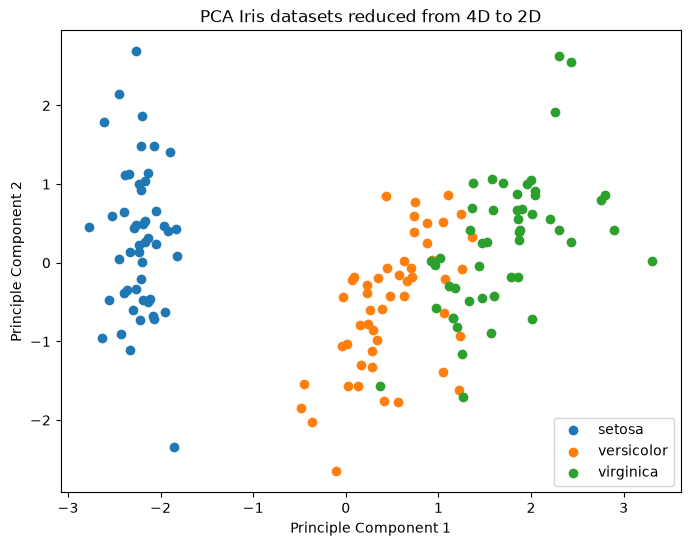

In [18]:
plt.figure(figsize=(8,6))

for class_id, species in enumerate(iris.target_names):
    mask = y == class_id

    plt.scatter(
        X_pca[mask,0],
        X_pca[mask,1],
        label=species
    )

plt.title("PCA Iris datasets reduced from 4D to 2D")
plt.xlabel("Principle Component 1")
plt.ylabel("Principle Component 2")
plt.legend()

In [19]:
explained_variance = pca.explained_variance_ratio_

cumulative_variance = np.cumsum(explained_variance)

In [20]:
explained_variance

array([0.72962445, 0.22850762])

In [21]:
cumulative_variance

array([0.72962445, 0.95813207])

Text(0.5, 1.0, 'Choosing the number of PCA components ')

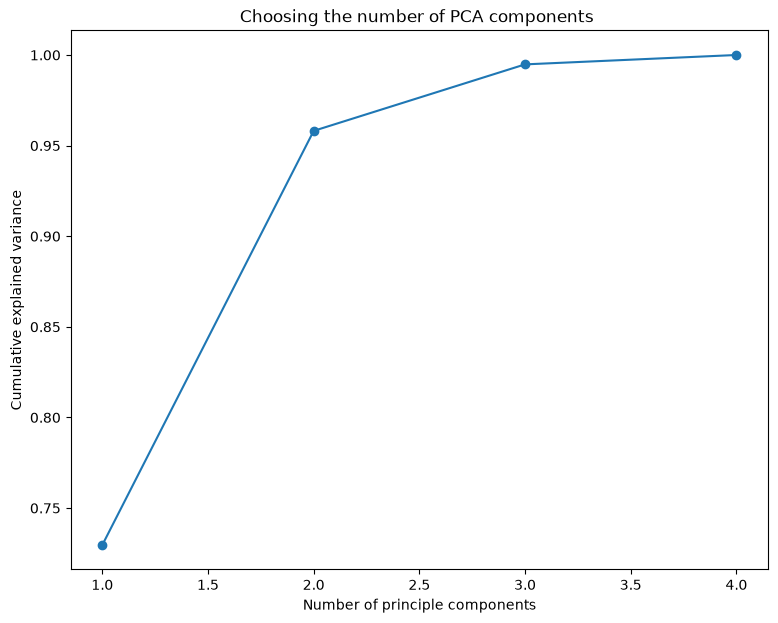

In [22]:
pca_full = PCA()

pca_full.fit(X_scaled)

cumulative = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(9,7))

plt.plot(
    range(1, len(cumulative) +1),
    cumulative,
    marker = 'o'
)

plt.xlabel("Number of principle components")
plt.ylabel("Cumulative explained variance")
plt.title("Choosing the number of PCA components ")